# 04 — JRESS Experiment 1 rerun: recovery before vs after the FTR fix

Paper grid with fewer crossing angles. *before*: recovery judges the standing resolution command (published implementation). *after*: it judges the desired (nominal) velocity, as the paper defines FTR. Results are appended to `results/jress_exp1_rerun.csv`; re-running skips finished cells.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.stats import beta

import blueskycdarr.episode as ep
from blueskycdarr import Config, SimulationConfig, UncertaintyConfig, FTR, PastCPA, ProbabilisticFTR
from blueskycdarr.aircraft import MULTIROTOR
from blueskycdarr.geo import track_components
from blueskycdarr.rng import child, root_seed_sequence
from blueskycdarr.scenario import PairwiseEncounter

# JRESS Experiment 1 (Table doe_exp1), reduced crossing-angle grid.
DPSI = [2.0, 4.0, 6.0, 10.0, 20.0, 45.0, 90.0, 135.0, 180.0]   # paper: 2, 4, ..., 180
UNCERTAINTY = [(3.0, 1.0), (3.0, 3.0), (10.0, 1.0), (10.0, 3.0)]  # (position, velocity) 95% CI [m, m/s]
RECOVERIES = {"PastCPA": PastCPA(), "FTR": FTR(), "ProbabilisticFTR": ProbabilisticFTR(gamma=0.999)}
VERSIONS = {"before": True, "after": False}   # before: judges the standing command (published); after: judges nominal
N_EPISODES = 100                               # 100 runs x 100 pairs = 10,000 encounters per cell
SPEED = 10.2889                                # 20 kt
SIM = SimulationConfig(dt=0.2, cdr_dt=1.0, t_max=600.0, done_timeout=10.0)
# blueskycdarr defaults match the paper: RPZ 50 m, lookahead 120 s, tlos 180 s (1.5 x lookahead),
# margin 1.05, 1 Hz perfect broadcast, M600 with 15 deg/s and 10 deg/s^2 turn limits.
STORE = Path("results/jress_exp1_rerun.csv")


def episode(seq, scenario, config, recovery, before):
    if before:
        tick, mask, cur = ep._cdr_tick, ep.recovered_mask, {}

        def tick_capture(world, ctx, state, streams, t, truth):
            cur["state"] = state
            return tick(world, ctx, state, streams, t, truth)

        def mask_commanded(rec, **kw):
            s = cur["state"]
            kw["desired_v"] = track_components(s.cmd_trk, s.cmd_gs)
            return mask(rec, **kw)

        ep._cdr_tick, ep.recovered_mask = tick_capture, mask_commanded
    try:
        return ep.run_episode(scenario, MULTIROTOR, config, seq, recovery)
    finally:
        if before:
            ep._cdr_tick, ep.recovered_mask = tick, mask

In [2]:
done = pd.read_csv(STORE) if STORE.exists() else pd.DataFrame()
key = lambda r: (r["dpsi"], r["pos_ci95"], r["vel_ci95"], r["recovery"], r["version"])
have = {key(r) for _, r in done.iterrows()}
seqs = [child(root_seed_sequence(7), j) for j in range(N_EPISODES)]   # same encounters in every cell

cells = [(d, p, v, r, ver) for d in DPSI for p, v in UNCERTAINTY for r in RECOVERIES for ver in VERSIONS
         if not (r == "PastCPA" and ver == "after")]                    # PastCPA never reads the changed input
t_start = time.perf_counter()
for i, (dpsi, pos, vel, rec, ver) in enumerate(cells):
    if (dpsi, pos, vel, rec, ver) in have:
        continue
    config = Config(uncertainty=UncertaintyConfig(pos, vel), simulation=SIM)
    scenario = PairwiseEncounter(speed=SPEED, dpsi=dpsi, dcpa=0.0, tlos=180.0)
    eps = Parallel(n_jobs=6)(delayed(episode)(s, scenario, config, RECOVERIES[rec], VERSIONS[ver]) for s in seqs)
    sep = np.concatenate([e.min_sep for e in eps])
    k, n = int((sep < config.conflict.rpz).sum()), sep.size
    row = {"dpsi": dpsi, "pos_ci95": pos, "vel_ci95": vel, "recovery": rec, "version": ver,
           "n_los": k, "n": n, "IPR": 1 - k / n,
           "IPR_lo": 1 - beta.ppf(0.975, k + 0.5, n - k + 0.5),
           "IPR_hi": 1 - (beta.ppf(0.025, k + 0.5, n - k + 0.5) if k else 0.0),
           "median_min_sep": float(np.median(sep)), "unsettled": sum(not e.settled for e in eps)}
    pd.DataFrame([row]).to_csv(STORE, mode="a", header=not STORE.exists(), index=False)
    print(f"[{i + 1}/{len(cells)}] {time.perf_counter() - t_start:6.0f} s  dpsi={dpsi:5.0f} pos={pos:4.0f} vel={vel:3.0f} "
          f"{rec:16s} {ver:6s} IPR={row['IPR']:.4f} ({k}/{n})", flush=True)
res = pd.read_csv(STORE)
res.loc[res.recovery == "PastCPA", "version"] = "both"
res

,dpsi,pos_ci95,vel_ci95,recovery,version,n_los,n,IPR,IPR_lo,IPR_hi,median_min_sep,unsettled
0,2.0,3.0,1.0,PastCPA,both,1506,10000,0.8494,0.842289,0.856308,51.456351,100
1,2.0,3.0,1.0,FTR,before,739,10000,0.9261,0.920849,0.931104,51.720011,100
2,2.0,3.0,1.0,FTR,after,2,10000,0.9998,0.999359,0.999958,56.419222,100
3,2.0,3.0,1.0,ProbabilisticFTR,before,0,10000,1.0000,0.999749,1.000000,67.332313,0
4,2.0,3.0,1.0,ProbabilisticFTR,after,0,10000,1.0000,0.999749,1.000000,71.128918,0
...,...,...,...,...,...,...,...,...,...,...,...,...
175,180.0,10.0,3.0,PastCPA,both,2,10000,0.9998,0.999359,0.999958,101.109431,0
176,180.0,10.0,3.0,FTR,before,2443,10000,0.7557,0.747205,0.764047,52.965988,0
177,180.0,10.0,3.0,FTR,after,10,10000,0.9990,0.998227,0.999486,67.580615,0
178,180.0,10.0,3.0,ProbabilisticFTR,before,53,10000,0.9947,0.993130,0.995984,72.658031,0


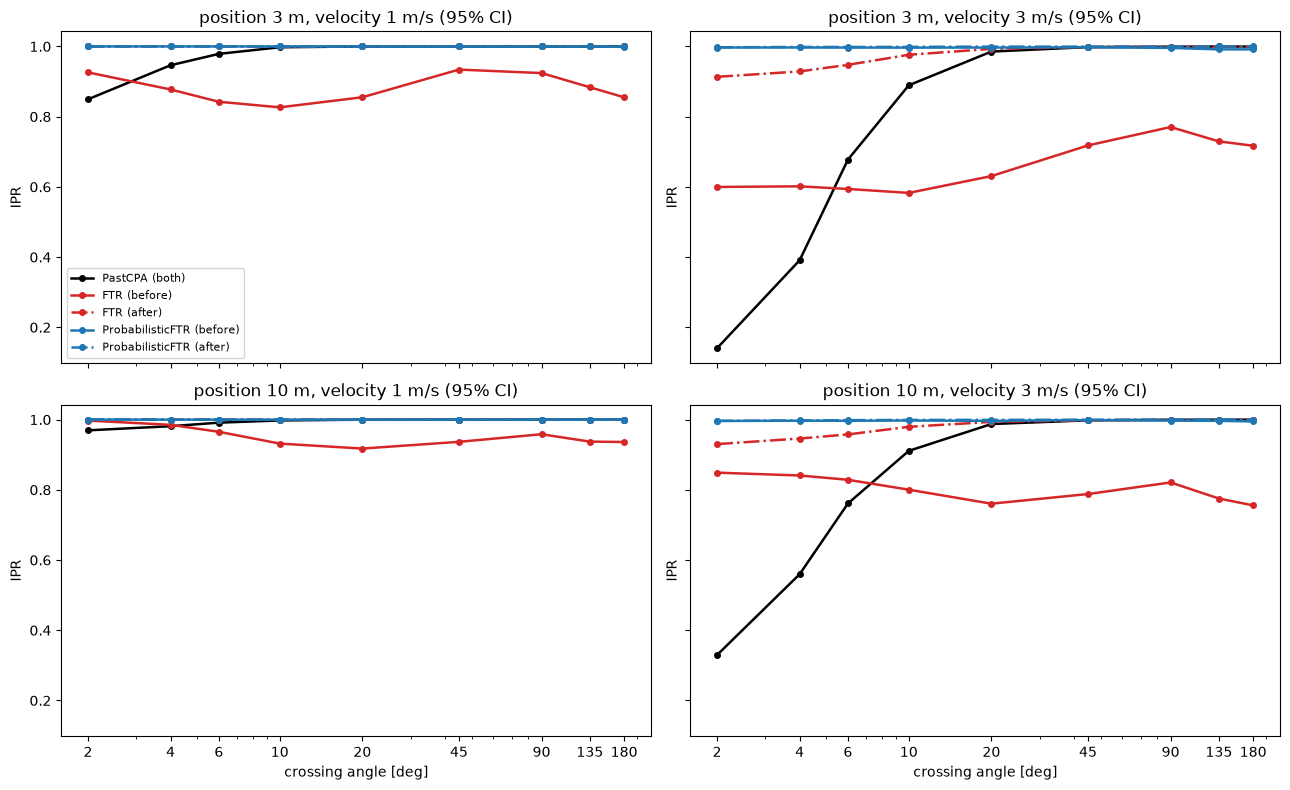

In [4]:
# IPR vs crossing angle, one panel per uncertainty level.
style = {("PastCPA", "both"): ("k", "-"), ("FTR", "before"): ("C3", "-"), ("FTR", "after"): ("C3", "-."),
         ("ProbabilisticFTR", "before"): ("C0", "-"), ("ProbabilisticFTR", "after"): ("C0", "-.")}
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
for ax, (pos, vel) in zip(axes.flat, UNCERTAINTY):
    sub = res[(res.pos_ci95 == pos) & (res.vel_ci95 == vel)]
    for (rec, ver), (c, ls) in style.items():
        s = sub[(sub.recovery == rec) & (sub.version == ver)].sort_values("dpsi")
        ax.plot(s.dpsi, s.IPR, color=c, ls=ls, marker="o", ms=4, lw=1.8, label=f"{rec} ({ver})")
    ax.set_title(f"position {pos:g} m, velocity {vel:g} m/s (95% CI)")
    ax.set_xscale("log"); ax.set_xticks(DPSI); ax.set_xticklabels([f"{d:g}" for d in DPSI])
    ax.set_ylabel("IPR")
for ax in axes[1]:
    ax.set_xlabel("crossing angle [deg]")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
# Angle-averaged IPR (trapezoid over 2-180 deg, approximating the paper's mean over its 2-deg grid),
# next to the abstract's published numbers: low = (3 m, 1 m/s), high = (10 m, 3 m/s).
def angle_mean(s):
    s = s.sort_values("dpsi")
    return np.trapezoid(s.IPR, s.dpsi) / (s.dpsi.max() - s.dpsi.min())

summary = (res.groupby(["pos_ci95", "vel_ci95", "recovery", "version"]).apply(angle_mean, include_groups=False)
              .rename("angle-mean IPR").unstack("version"))
published = {(3.0, 1.0, "FTR"): 0.956, (3.0, 1.0, "ProbabilisticFTR"): 0.999,
             (10.0, 3.0, "FTR"): 0.789, (10.0, 3.0, "ProbabilisticFTR"): 0.989}
summary["published (abstract)"] = [published.get(i, np.nan) for i in summary.index]
smallest = res[(res.dpsi == min(DPSI)) & (res.pos_ci95 == 10.0) & (res.vel_ci95 == 3.0)][["recovery", "version", "IPR", "n_los"]]
print(f"At {min(DPSI):g} deg, high uncertainty (published: FTR 0.430, ProbabilisticFTR >= 0.922):")
print(smallest.to_string(index=False))
summary.round(4)

At 2 deg, high uncertainty (published: FTR 0.430, ProbabilisticFTR >= 0.922):
        recovery version    IPR  n_los
         PastCPA    both 0.3295   6705
             FTR  before 0.8489   1511
             FTR   after 0.9302    698
ProbabilisticFTR  before 0.9961     39
ProbabilisticFTR   after 0.9965     35


version                              after  before    both  \
pos_ci95 vel_ci95 recovery                                   
3.0      1.0      FTR               0.9999  0.8946     NaN   
                  PastCPA              NaN     NaN  0.9981   
                  ProbabilisticFTR  1.0000  0.9998     NaN   
         3.0      FTR               0.9955  0.7161     NaN   
                  PastCPA              NaN     NaN  0.9764   
                  ProbabilisticFTR  0.9995  0.9947     NaN   
10.0     1.0      FTR               1.0000  0.9415     NaN   
                  PastCPA              NaN     NaN  0.9994   
                  ProbabilisticFTR  1.0000  0.9999     NaN   
         3.0      FTR               0.9959  0.7884     NaN   
                  PastCPA              NaN     NaN  0.9819   
                  ProbabilisticFTR  0.9997  0.9969     NaN   

version                             published (abstract)  
pos_ci95 vel_ci95 recovery                                
3.0      1.0      FTR                              0.956  
                  PastCPA                            NaN  
                  ProbabilisticFTR                 0.999  
         3.0      FTR                                NaN  
                  PastCPA                            NaN  
                  ProbabilisticFTR                   NaN  
10.0     1.0      FTR                                NaN  
                  PastCPA                            NaN  
                  ProbabilisticFTR                   NaN  
         3.0      FTR                              0.789  
                  PastCPA                            NaN  
                  ProbabilisticFTR                 0.989